# Numerical Solution of ODEs: The Leapfrog Particle Pusher for an IVP #

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

omega_p = 1.0
x0, v0, T = 0.5, 0.0, 20.0

def x_exact(t): return 0.5 * np.cos(omega_p * t)
def v_exact(t): return -0.5 * np.sin(omega_p * t)

# The leapfrog step function #

In [2]:
def accel(x, omega_p=omega_p):
    return -omega_p**2 * x

def leapfrog(x, v, h, omega_p=omega_p):
    v_new = v + h * accel(x, omega_p)   
    x_new = x + h * v_new              
    return x_new, v_new

In [3]:
h = 0.1
xp = np.array([0.5, 0.3, -0.2, 0.05])        # 4 particles
vp = np.zeros_like(xp) - 0.5*h*accel(xp)      # staggered start (Task 2)
N = int(round(T / h))
for _ in range(N):
    xp, vp = leapfrog(xp, vp, h)

print("Particle positions at t = 20 (leapfrog):", np.round(xp, 5))
print("Exact                              :", np.round(np.array([0.5, 0.3, -0.2, 0.05])*np.cos(T), 5))

Particle positions at t = 20 (leapfrog): [ 0.20023  0.12014 -0.08009  0.02002]
Exact                              : [ 0.20404  0.12242 -0.08162  0.0204 ]


## Initializing the half step

The initial condition gives $v$ at $t=0$, but leapfrog needs $v^{-1/2}$. Move the velocity back half a step:

$$
v^{-1/2} = v^0 - \frac{h}{2}\,a(x^0), \qquad a(x) = -\omega_p^2 x.
$$

This is one Euler step of size $h/2$. Its local error is $O(h^2)$ and it is applied only once, so it does not reduce the global second-order accuracy.

In [4]:
def init_half_step(x0, v0, h, omega_p=omega_p):

    return v0 - 0.5 * h * accel(x0, omega_p)

def integrate(h, T=T, x0=x0, v0=v0, staggered=True, omega_p=omega_p, nsteps=None):
    N = nsteps if nsteps is not None else int(round(T / h))
    x = np.empty(N + 1)
    v = np.empty(N)
    x[0] = x0
    vh = init_half_step(x0, v0, h, omega_p) if staggered else v0
    for n in range(N):
        x[n+1], vh = leapfrog(x[n], vh, h, omega_p)
        v[n] = vh
    t_x = h * np.arange(N + 1)
    t_v = h * (np.arange(N) + 0.5)
    return t_x, x, t_v, v
print("h = 0.1:  v^{-1/2} =", init_half_step(x0, v0, 0.1),
      "   exact v(-h/2) =", v_exact(-0.05))

h = 0.1:  v^{-1/2} = 0.025    exact v(-h/2) = 0.024989584635339165


## Checking the implementation ($h = 0.1$)

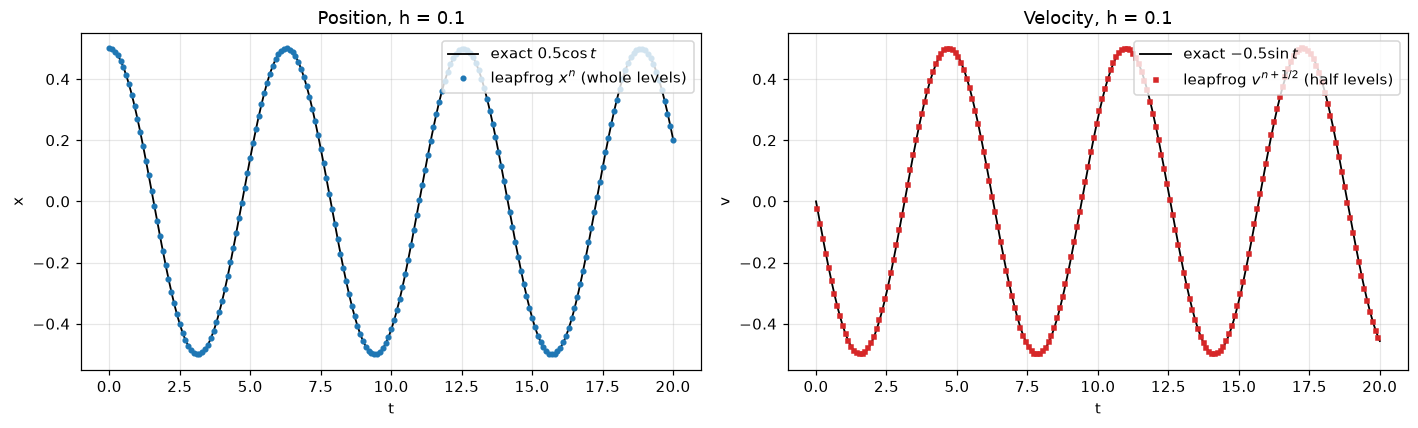

max |x - x_exact| = 3.815e-03
max |v - v_exact| = 3.931e-03


In [5]:
h = 0.1
t_x, x, t_v, v = integrate(h)
tt = np.linspace(0, T, 2000)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(tt, x_exact(tt), "k-", lw=1.2, label="exact $0.5\\cos t$")
ax[0].plot(t_x, x, "o", ms=3, color="C0", label="leapfrog $x^n$ (whole levels)")
ax[0].set(xlabel="t", ylabel="x", title="Position, h = 0.1"); ax[0].legend(loc="upper right")

ax[1].plot(tt, v_exact(tt), "k-", lw=1.2, label="exact $-0.5\\sin t$")
ax[1].plot(t_v, v, "s", ms=3, color="C3", label="leapfrog $v^{n+1/2}$ (half levels)")
ax[1].set(xlabel="t", ylabel="v", title="Velocity, h = 0.1"); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

print(f"max |x - x_exact| = {np.max(np.abs(x - x_exact(t_x))):.3e}")
print(f"max |v - v_exact| = {np.max(np.abs(v - v_exact(t_v))):.3e}")

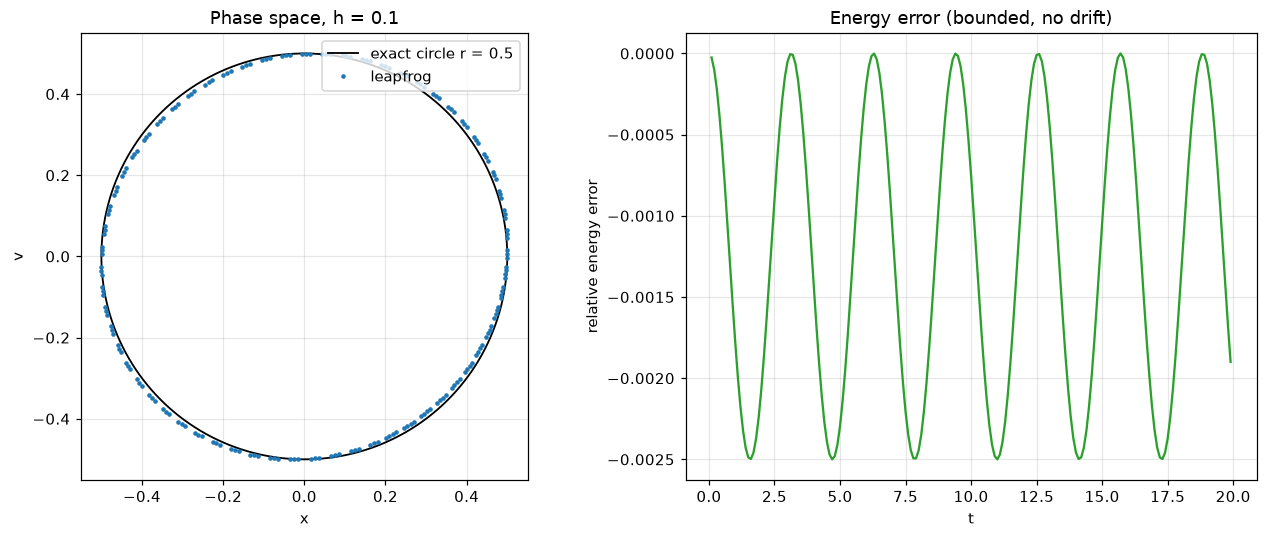

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
th = np.linspace(0, 2*np.pi, 400)
ax[0].plot(0.5*np.cos(th), -0.5*np.sin(th), "k-", lw=1.2, label="exact circle r = 0.5")
# x^{n+1} and v^{n+1/2} are the values available after each step
ax[0].plot(x[1:], v, ".", ms=4, color="C0", label="leapfrog")
ax[0].set_aspect("equal"); ax[0].set(xlabel="x", ylabel="v", title="Phase space, h = 0.1")
ax[0].legend(loc="upper right")

# Discrete invariant: average v at whole levels to get an energy estimate
v_whole = 0.5*(v[:-1] + v[1:])           # ~ v at t_1 .. t_{N-1}
E = 0.5*v_whole**2 + 0.5*omega_p**2*x[1:-1]**2
ax[1].plot(t_x[1:-1], E/0.125 - 1, color="C2")
ax[1].set(xlabel="t", ylabel="relative energy error", title="Energy error (bounded, no drift)")
plt.tight_layout(); plt.show()

**Observations.**
- Positions and velocities lie on the exact curves when each is plotted at its own time level.
- The phase-space trajectory is a closed curve of radius $\approx 0.5$. It does not spiral inward or outward, even after more than three periods.
- The energy error oscillates with a small bounded amplitude and shows no secular drift. This is because leapfrog is **symplectic** (time-reversible), unlike forward Euler (energy grows) or RK4 (energy slowly decays). This property is why it is used in long PIC runs.
- Because $x$ and $v$ are at different times, the discrete orbit is a very slightly tilted ellipse; at $h = 0.1$ this is invisible.

## Convergence study

Maximum error in $x$ over $0 \le t \le 20$, and observed order $p = \log_2\!\big(e(h)/e(h/2)\big)$, for both the staggered start $v^{-1/2} = v^0 - \tfrac h2 a(x^0)$ and the unstaggered start $v^{-1/2} = v^0$.

In [7]:
hs = [0.2, 0.1, 0.05, 0.025]

def conv_table(staggered):
    errs = []
    for h in hs:
        t_x, x, _, _ = integrate(h, staggered=staggered)
        errs.append(np.max(np.abs(x - x_exact(t_x))))
    errs = np.array(errs)
    p = np.r_[np.nan, np.log2(errs[:-1] / errs[1:])]
    return errs, p

e_s, p_s = conv_table(True)
e_u, p_u = conv_table(False)

print(f"{'':8s}|{'   Staggered start':^28s}|{'  Unstaggered start':^28s}")
print(f"{'h':>8s}|{'max error e(h)':>17s}{'order p':>11s}|{'max error e(h)':>17s}{'order p':>11s}")
print("-"*66)
for h, a, b, c, d in zip(hs, e_s, p_s, e_u, p_u):
    pa = "   —" if np.isnan(b) else f"{b:8.3f}"
    pb = "   —" if np.isnan(d) else f"{d:8.3f}"
    print(f"{h:8.3f}|{a:17.4e}{pa:>11s}|{c:17.4e}{pb:>11s}")

        |        Staggered start     |      Unstaggered start     
       h|   max error e(h)    order p|   max error e(h)    order p
------------------------------------------------------------------
   0.200|       1.5396e-02          —|       6.4557e-02          —
   0.100|       3.8153e-03      2.013|       2.8628e-02      1.173
   0.050|       9.5169e-04      2.003|       1.3402e-02      1.095
   0.025|       2.3779e-04      2.001|       6.4754e-03      1.049


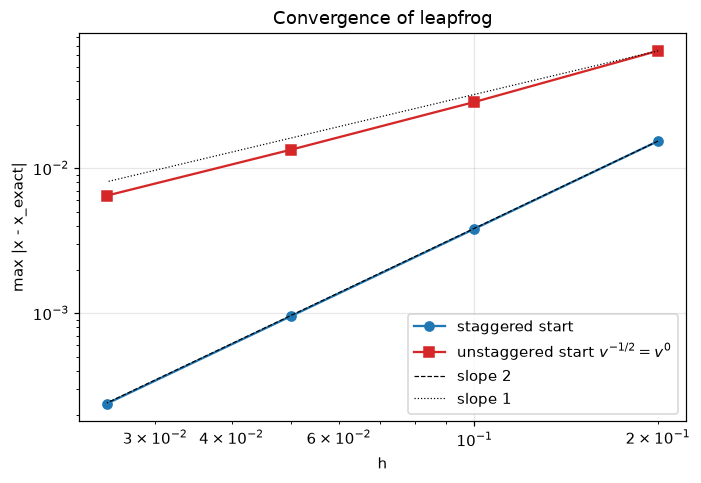

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
hs_a = np.array(hs)
ax.loglog(hs_a, e_s, "o-", color="C0", label="staggered start")
ax.loglog(hs_a, e_u, "s-", color="C3", label="unstaggered start $v^{-1/2}=v^0$")
ax.loglog(hs_a, e_s[0]*(hs_a/hs_a[0])**2, "k--", lw=0.8, label="slope 2")
ax.loglog(hs_a, e_u[0]*(hs_a/hs_a[0])**1, "k:", lw=0.8, label="slope 1")
ax.set(xlabel="h", ylabel="max |x - x_exact|", title="Convergence of leapfrog")
ax.legend(); plt.tight_layout(); plt.show()

In [9]:
for h in hs:
    exact = v_exact(-h/2)
    print(f"h={h:5.3f}:  exact v(-h/2)={exact:+.5f}   "
          f"staggered err={abs(init_half_step(x0,v0,h)-exact):.2e}   "
          f"unstaggered err={abs(v0-exact):.2e}")

h=0.200:  exact v(-h/2)=+0.04992   staggered err=8.33e-05   unstaggered err=4.99e-02
h=0.100:  exact v(-h/2)=+0.02499   staggered err=1.04e-05   unstaggered err=2.50e-02
h=0.050:  exact v(-h/2)=+0.01250   staggered err=1.30e-06   unstaggered err=1.25e-02
h=0.025:  exact v(-h/2)=+0.00625   staggered err=1.63e-07   unstaggered err=6.25e-03


## Equivalence to the central-difference formula (order of the method)

Write the drift for two consecutive steps:

$$
x^{n+1} - x^n = h\,v^{n+1/2}, \qquad x^n - x^{n-1} = h\,v^{n-1/2}.
$$

Subtracting,

$$
x^{n+1} - 2x^n + x^{n-1} = h\left(v^{n+1/2} - v^{n-1/2}\right).
$$

The kick gives $v^{n+1/2} - v^{n-1/2} = h\,a(x^n) = -\omega_p^2 h\,x^n$. Substituting eliminates $v$:

$$
\boxed{\,x^{n+1} - 2x^n + x^{n-1} = -\omega_p^2 h^2\,x^n\,}
$$

This is the standard central-difference (Störmer–Verlet) approximation of $\ddot x = -\omega_p^2 x$.

**Order.** Taylor-expand the exact solution about $t_n$:

$$
x(t_n \pm h) = x \pm h\dot x + \frac{h^2}{2}\ddot x \pm \frac{h^3}{6}\dddot x + \frac{h^4}{24}x^{(4)} \pm \cdots
$$

Adding the two expansions, the odd terms cancel:

$$
\frac{x(t_{n+1}) - 2x(t_n) + x(t_{n-1})}{h^2} = \ddot x(t_n) + \frac{h^2}{12}x^{(4)}(t_n) + O(h^4).
$$

The local truncation error is $\tau = \frac{h^2}{12}x^{(4)} = O(h^2)$, so the method is **second-order accurate**, consistent with $p \approx 2$ in Task 4.

Numerical confirmation that the leapfrog sequence satisfies the recurrence:

In [10]:
h = 0.1
t_x, x, _, _ = integrate(h)
residual = x[2:] - 2*x[1:-1] + x[:-2] + omega_p**2 * h**2 * x[1:-1]
print(f"max |x^(n+1) - 2x^n + x^(n-1) + w^2 h^2 x^n| = {np.max(np.abs(residual)):.2e}  (round-off level)")

max |x^(n+1) - 2x^n + x^(n-1) + w^2 h^2 x^n| = 7.37e-17  (round-off level)


## Stability limit

Seek solutions $x^n = r^n$ of the recurrence $x^{n+1} - 2x^n + x^{n-1} = -\omega_p^2 h^2 x^n$. Dividing by $r^{n-1}$ gives the characteristic equation

$$
r^2 - b\,r + 1 = 0, \qquad b = 2 - \omega_p^2 h^2, \qquad r_{1,2} = \frac{b \pm \sqrt{b^2 - 4}}{2}.
$$

Key fact: $r_1 r_2 = 1$.

- **$|b| < 2 \iff 0 < \omega_p h < 2$:** $b^2 - 4 < 0$, so the roots are complex conjugates with $|r_1|^2 = r_1\bar r_1 = r_1 r_2 = 1$. Hence $|r| = 1$ and $r = e^{\pm i\theta}$ with $\cos\theta = 1 - \tfrac12\omega_p^2h^2$. The solution oscillates with constant amplitude: **stable** (and non-dissipative).
- **$\omega_p h = 2$:** $b = -2$, double root $r = -1$, giving $x^n = (A + Bn)(-1)^n$: linear growth, marginal.
- **$\omega_p h > 2$:** $b < -2$, two real negative roots with product 1, so one has $|r| > 1$: the solution grows exponentially while flipping sign every step, **unstable**.

$$
{\text{Stability condition: } \omega_p h < 2}
$$

### Numerical confirmation

With $h \approx 2$ the interval $0 \le t \le 20$ contains only about 10 steps, so we run 60 steps for each case to make the behaviour clear.

In [11]:
cases = [1.9, 1.99, 2.01, 2.1]
nsteps = 60

print(f"{'w_p h':>6s} | {'roots r':^34s} | {'max|r|':>7s} | {'|x_60|':>10s}")
print("-"*68)
results = {}
for wh in cases:
    h = wh / omega_p
    t_x, x, _, _ = integrate(h, nsteps=nsteps)
    r = np.roots([1, -(2 - wh**2), 1])
    results[wh] = x
    rs = ", ".join(f"{z.real:+.4f}{z.imag:+.4f}j" for z in r)
    print(f"{wh:6.2f} | {rs:^34s} | {np.max(np.abs(r)):7.4f} | {abs(x[-1]):10.3e}")

 w_p h |              roots r               |  max|r| |     |x_60|
--------------------------------------------------------------------
  1.90 |  -0.8050+0.5933j, -0.8050-0.5933j  |  1.0000 |  4.589e-01
  1.99 |  -0.9801+0.1988j, -0.9801-0.1988j  |  1.0000 |  4.233e-01
  2.01 |  -1.2213+0.0000j, -0.8188+0.0000j  |  1.2213 |  4.049e+04
  2.10 |  -1.8773+0.0000j, -0.5327+0.0000j  |  1.8773 |  6.462e+15
